## Who patents?

                       Tipo  Numero_Family
                    COMPANY           6947
                 UNIVERSITY           2270
             GOV NON-PROFIT            501
       COMPANY + INDIVIDUAL            426
                 INDIVIDUAL            309
       COMPANY + UNIVERSITY            234
GOV NON-PROFIT + UNIVERSITY            118
    INDIVIDUAL + UNIVERSITY            114
       Other Collaborations            256
              TOTALE FAMILY          11175
              TOTALE ENTITÀ           2788


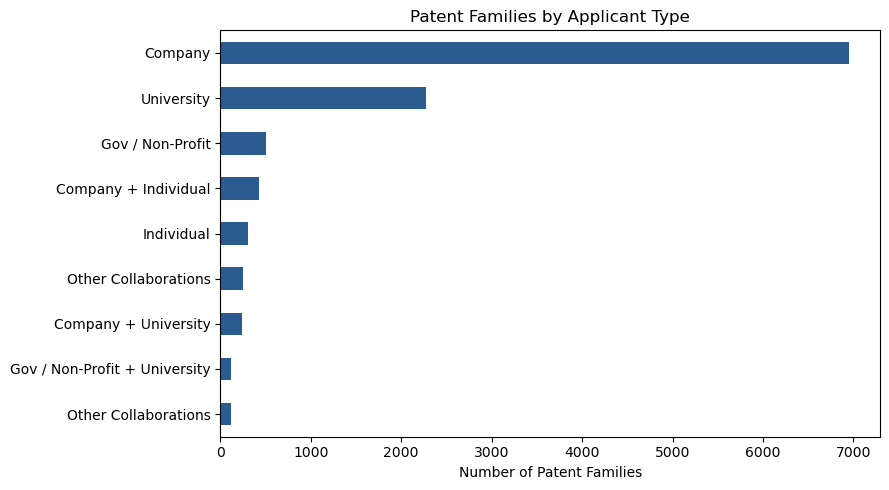

In [6]:
import pandas as pd


def riepilogo_finale(file_harm: str = "harmonization_output.csv",file_qc: str = "qc_applicants_PROD.csv",top_n: int = 8):
    df_harm = pd.read_csv(file_harm)
    df_qc = pd.read_csv(file_qc)

    # Extract INDIVIDUAL rows from qc and populate harmonized_name_final
    df_ind = df_qc[df_qc["psn_sector"] == "INDIVIDUAL"].copy()
    df_ind["harmonized_name_final"] = df_ind["psn_name"]   
    df = pd.concat([df_harm, df_ind], ignore_index=True)

    # Propagate known psn_sector to UNKNOWN/NaN rows with the same harmonized_name_final
    known = df[df["psn_sector"].notna() & (df["psn_sector"] != "UNKNOWN")]
    sector_map = known.groupby("harmonized_name_final")["psn_sector"].agg(
        lambda s: s.mode().iloc[0]
    )
    df["tipo"] = (df["psn_sector"].replace("UNKNOWN", pd.NA)
        .fillna(df["harmonized_name_final"].map(sector_map))
    )

    # Remove remaining UNKNOWN / NaN rows
    df = df[df["tipo"].notna()].copy()

   
    fam_tipo = df.groupby("docdb_family_id")["tipo"].apply(
        lambda s: " + ".join(sorted(s.unique()))
    )
    tabella = (
        fam_tipo.value_counts()
        .rename_axis("Tipo")
        .reset_index(name="Numero_Family")
    )

    # Group minor combinations beyond top_n into Other Collaborations
    if len(tabella) > top_n:
        other = pd.DataFrame([{
            "Tipo": "Other Collaborations",
            "Numero_Family": tabella.iloc[top_n:]["Numero_Family"].sum(),
        }])
        tabella = pd.concat([tabella.iloc[:top_n], other], ignore_index=True)

    # Add total families and total distinct entities at the bottom
    totali = pd.DataFrame([
        {
            "Tipo": "TOTALE FAMILY",
            "Numero_Family": df["docdb_family_id"].nunique(),
        },
        {
            "Tipo": "TOTALE ENTITÀ",
            "Numero_Family": df["harmonized_name_final"].nunique(),
        },
    ])
    tabella = pd.concat([tabella, totali], ignore_index=True)

    print(tabella.to_string(index=False))
    return df, tabella


def plot_top_applicant_types(tabella_riepilogo: pd.DataFrame, top_n: int = 8):
    # Filter out total rows and group remaining categories into Other Collaborations
    df = tabella_riepilogo[~tabella_riepilogo["Tipo"].str.startswith("TOTALE")].nlargest(len(tabella_riepilogo), "Numero_Family")
    other = pd.DataFrame([{"Tipo": "Other Collaborations", "Numero_Family": df.iloc[top_n:]["Numero_Family"].sum()}])
    plot_df = pd.concat([df.iloc[:top_n], other], ignore_index=True).iloc[::-1]

    # Format labels in English and plot horizontal bar chart
    labels = plot_df["Tipo"].str.title().str.replace("Gov Non-Profit", "Gov / Non-Profit")
    ax = plot_df.plot.barh(x="Tipo", y="Numero_Family", legend=False, color="#2b5c8f", figsize=(9, 5), title="Patent Families by Applicant Type")
    ax.set_yticklabels(labels)
    ax.set_xlabel("Number of Patent Families")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

    
df_completo, tabella_riepilogo = riepilogo_finale()
plot_top_applicant_types(tabella_riepilogo)

## Concentration

In [15]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # Lotka regression and Kendall's tau
def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def six_measures(patents_per_firm):
    "All the measures for one group of firms, as one row of a table."
    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }



In [16]:
def compute_concentration_table(df_completo: pd.DataFrame) -> pd.DataFrame:
    # Define sector subsets
    groups = {
        "All Entities": df_completo,
        "Companies": df_completo[df_completo["tipo"] == "COMPANY"],
        "Universities": df_completo[df_completo["tipo"] == "UNIVERSITY"],
        "Gov / Non-Profit": df_completo[df_completo["tipo"] == "GOV NON-PROFIT"],
        "Institutional": df_completo[df_completo["tipo"] != "INDIVIDUAL"],
    }

    # Compute six concentration measures per group using distinct patent families per entity
    return pd.DataFrame.from_dict(
        {k: six_measures(v.groupby("harmonized_name_final")["docdb_family_id"].nunique().values) for k, v in groups.items()},
        orient="index",
    )
concentration_table = compute_concentration_table(df_completo)
print(concentration_table.to_string())

                  firms  patents (sum over firms)        CV    CR4 (%)    CR8 (%)        HH       1/HH   Lotka L  Lotka p-value      Gini
All Entities       2788                     14507  5.443788  16.047425  22.154822  0.010984  91.039124 -1.064117   2.428364e-24  0.738358
Companies           805                      8493  4.833973  27.410809  37.842929  0.030234  33.075484 -0.797382   1.288325e-17  0.823595
Universities        458                      3018  1.923341  13.850232  20.212061  0.010243  97.630330 -1.160562   3.451834e-15  0.657208
Gov / Non-Profit    115                       802  1.785762  30.548628  45.012469  0.036184  27.636161 -0.836430   4.464800e-08  0.650287
Institutional      1396                     12424  4.457014  18.737927  25.869285  0.014936  66.952036 -0.980786   7.378566e-25  0.776017


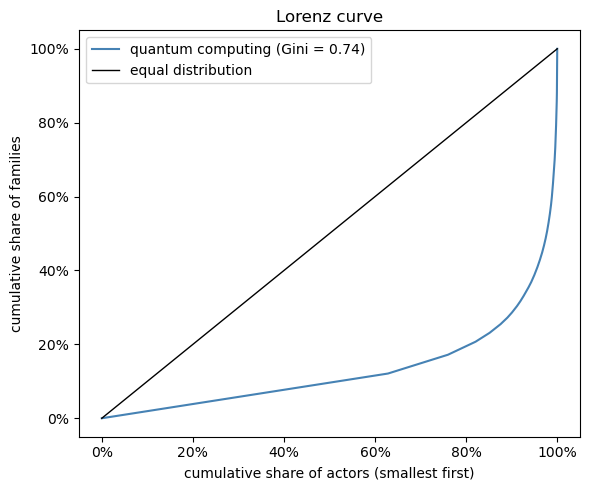

In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Compute distinct families per actor across the entire dataset
x_all = (
    df_completo.groupby("harmonized_name_final")["docdb_family_id"]
    .nunique()
    .values
)

fig, ax = plt.subplots(figsize=(6, 5))

# Lorenz curve and Gini index
share_of_firms, share_of_patents = lorenz_curve(x_all)
ax.plot(
    share_of_firms,
    share_of_patents,
    color="steelblue",
    label=f"quantum computing (Gini = {gini(x_all):.2f})",
)
ax.plot([0, 1], [0, 1], color="black", lw=1, label="equal distribution")
ax.set(
    title="Lorenz curve",
    xlabel="cumulative share of actors (smallest first)",
    ylabel="cumulative share of families",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()

plt.tight_layout()
plt.show()

## Consolidate

In [22]:
import numpy as np
import pandas as pd

SPLIT_YEAR = 2015
MIN_FAMILIES = 1

# Filter up to 2022 and deduplicate actor-family links
links = (
    df_completo[df_completo["family_year"] <= 2022][
        ["harmonized_name_final", "docdb_family_id", "family_year", "tipo"]
    ]
    .drop_duplicates(subset=["harmonized_name_final", "docdb_family_id"])
    .rename(
        columns={
            "harmonized_name_final": "actor",
            "docdb_family_id": "family",
            "family_year": "year",
        }
    )
)


before = links[links["year"] < SPLIT_YEAR].groupby("actor")["family"].nunique()

actors = pd.DataFrame({
    "tipo": links.groupby("actor")["tipo"].agg(lambda s: s.mode().iloc[0]),
    "families": links.groupby("actor")["family"].nunique(),
    "first_year": links.groupby("actor")["year"].min(),
})
actors["status"] = np.where(
    actors.index.isin(before[before >= MIN_FAMILIES].index),
    "incumbent",
    "entrant",
)

# Top 15 actors by total families (up to 2022)
top15 = (
    actors.sort_values(by="families", ascending=False)
    .head(15)
    .reset_index()
    .rename(columns={"actor": "applicant"})
)
display(top15)

,applicant,tipo,families,first_year,status
0,IBM INTERNATIONAL BUSINESS MACHINES,COMPANY,667,1994,incumbent
1,ORIGIN QUANTUM COMPUTING TECH HEFEI,COMPANY,651,2017,entrant
2,MICROSOFT TECH LICENSING,COMPANY,224,2004,incumbent
3,BEIJING BAIDU NETCOM SCIENCE TECH,COMPANY,215,2019,entrant
4,D WAVE SYSTEMS,COMPANY,212,1999,incumbent
5,国际商业机器,COMPANY,198,2011,incumbent
6,GOOGLE,COMPANY,187,2013,incumbent
7,INTEL,COMPANY,163,2000,incumbent
8,FUJITSU,COMPANY,158,1993,incumbent
9,RUBAN QUANTUM TECH,COMPANY,153,2018,entrant


,active_applicants,new_to_the_sector,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,
2005,125,95,73,58.4,65.0
2006,124,82,74,59.7,65.3
2007,192,137,105,54.7,65.5
2008,169,113,113,66.9,63.9
2009,128,75,84,65.6,67.8
2010,127,91,82,64.6,62.7
2011,159,108,107,67.3,67.6
2012,88,55,51,58.0,56.0
2013,78,35,19,24.4,36.8


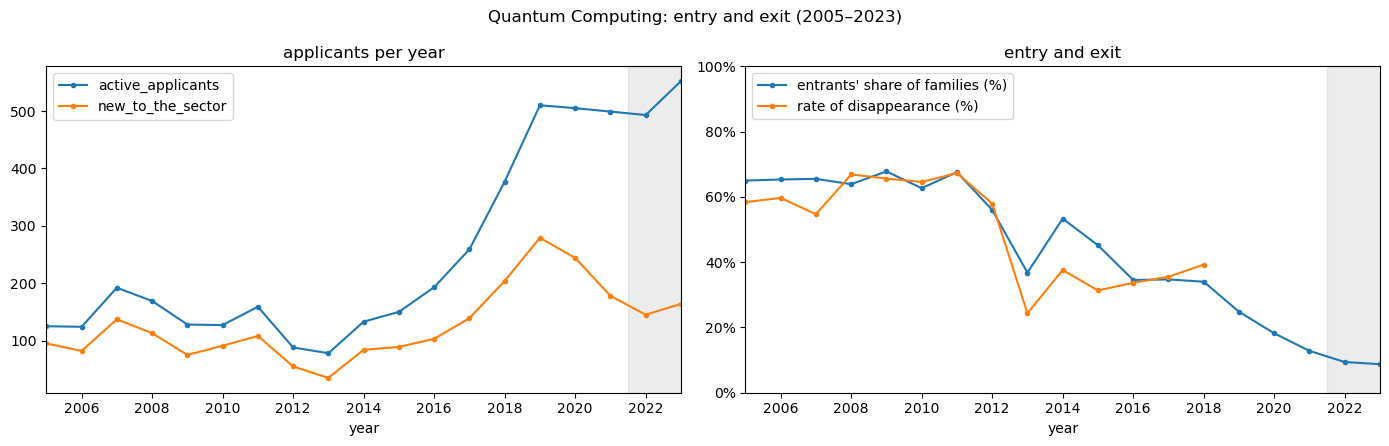

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SECTOR_NAME = "Quantum Computing"
YEAR_MIN = 2005
LAST_COMPLETE_YEAR = 2021
YEAR_MAX = int(df_completo["family_year"].max())

# Deduplicate actor-family links (keep full history to compute true first_year/last_year)
links = (
    df_completo[["harmonized_name_final", "docdb_family_id", "family_year"]]
    .drop_duplicates()
    .rename(columns={
        "harmonized_name_final": "applicant",
        "docdb_family_id": "unit_id",
        "family_year": "year",
    })
)

by_applicant = links.groupby("applicant")
first_year = by_applicant["year"].min()
last_year = by_applicant["year"].max()

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, "rate of disappearance (%)"] = np.nan

# Share of each year's families with at least one applicant new to the sector
links_new = links.assign(new=links["year"] == links["applicant"].map(first_year))
entry_exit["entrants' share of families (%)"] = (
    links_new.groupby(["year", "unit_id"])["new"].any().groupby("year").mean() * 100
)

# Filter from 2005 onwards for table and plots
entry_exit = entry_exit.loc[entry_exit.index >= YEAR_MIN]
display(entry_exit.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
entry_exit[["active_applicants", "new_to_the_sector"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="applicants per year", xlabel="year", xlim=(YEAR_MIN, YEAR_MAX))

entry_exit[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="entry and exit", xlabel="year", ylim=(0, 100), xlim=(YEAR_MIN, YEAR_MAX))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))

for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)

fig.suptitle(f"{SECTOR_NAME}: entry and exit (2005–{YEAR_MAX})")
plt.tight_layout()
plt.show()

## Which Subfields go faster? 

Take from step 1 I think

## Pest